# MenuMind — итоговая проверка LLM, версия 2

AAI-2602M · Adilzhan Kurmet · Nursultan Tolegenov · Zeiin Issakulov

**Исследование:** сравнить простой и подробный промпт на RU/KK, проверить
факты, перегенерацию, тон, длину, ошибки, задержку и стоимость.
**Модель:** gpt-5.6-luna, реальные запросы; веса модели не обучались.

После первого эксперимента улучшены промпт, словарные проверки и перегенерация.
Теперь разрешён один запрос исправления в пределах общего таймаута 8,5 секунды.
Он учитывается в стоимости и задержке. Для итоговой проверки взяты 8 новых блюд
(16 языковых примеров), отсутствующих в предыдущем эксперименте. Промпт и код
зафиксированы до запуска holdout. Первые 32 примера теперь считаются материалом
разработки; сравнивать их результаты с новой выборкой как причинный эффект нельзя.

**Run All работает без API-ключа и сети:** входы, ответы и снимок кода встроены.
Соседние файлы проверяются по SHA-256. Новые платные запросы выполняются отдельно
скриптом `run.mjs`; старые результаты не перезаписываются.

In [1]:
# При необходимости: %pip install -r requirements.txt
from pathlib import Path
from io import StringIO
import json, zlib, base64, hashlib, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid',palette='colorblind')
pd.set_option('display.max_colwidth',130)
ROOT=Path.cwd()
OUT=ROOT/'analysis'; OUT.mkdir(exist_ok=True)
(OUT/'figures').mkdir(exist_ok=True)
def fig(name):
    plt.tight_layout(); plt.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight'); plt.show()

In [2]:
BLOB='...'
HASHES={'old-inputs.json': 'da0851ef3f045a1617ba65bdeaf7c02f192b2987d3a2473e4c41e636aa02b59f', 'inputs.json': 'a0d39c30b065e9781a70844f453edb8a2c932085253ae8d66a215e57d97bcfb9', 'pricing.json': 'c4ac68f94c104d8b3405e9357876c21afd92ba66040da2d3deab55c6226e8861', 'results/browser.json': '98e0b4647f9467062eb32bedf1c673af693b607dce674f315ef5e35ec771ec18', 'results/contract.json': 'c459609685ca10038d702678c1866cfda0d627a14758b5fda1f24ae7d5c213df', 'results/dev-manifest.json': 'd091eb19e3e64159e814409c6ff8d5757c567ec58efdc3fe6606a3b480caea2b', 'results/final-manifest.json': 'bf18d7c9cad627e443268e496bfbc7fca74c985ba036a4e409ccbc1e2beb38a8', 'results/freeze.json': 'c3982cbff3cb8373e447d597707c18accf967f302a412c982759e8251d1b9605', 'results/refined-manifest.json': 'f27e096d0a93e1ebf5b5e6f5b3db31a443d835ab0fc0e2b451f7a6b624845b5a', 'results/tones-manifest.json': 'ec5ebab22e3cd3626870bbca74de15353089a941de66f2275646439d9b3b6167', 'results/dev.jsonl': '7afdfb1ca2b592b8e35cecadddb76fd36d2c0c03cc187ad459840f7b4510103c', 'results/final.jsonl': '662d9ad86e622019e172379964f5ca4308c0d5a39484dd8362cbb062568592ab', 'results/refined.jsonl': 'd3fe0db627c2f813030703a9ff3395cbd1640221fc3164c641dd68934a5545c0', 'results/tones.jsonl': 'c495fc5a6a5b3e604c250622f106b5b97fd4ae70c53ec2167ff2e006a7fc7af5'}
snapshot=json.loads(zlib.decompress(base64.b64decode(BLOB)))
def read(name):
    p=ROOT/name
    value=p.read_text(encoding='utf-8') if p.exists() else snapshot[name]
    assert hashlib.sha256(value.encode()).hexdigest()==HASHES[name],name
    return value
def load(name):return json.loads(read(name))
def lines(name):return [json.loads(s) for s in read(name).splitlines() if s]
old=[{**r,'split':'dev'} for r in load('old-inputs.json')]
current=load('inputs.json')
raw=pd.DataFrame(old+current)
print('Raw rows:',len(raw),'| columns:',len(raw.columns))
display(raw[['id','group','language','split','completeness']].head())

Raw rows: 54 | columns: 9


,id,group,language,split,completeness
0,pumpkin-ru,pumpkin,ru,dev,complete
1,pumpkin-kk,pumpkin,kk,dev,complete
2,chicken-ru,chicken,ru,dev,complete
3,chicken-kk,chicken,kk,dev,complete
4,tomato-ru,tomato,ru,dev,complete


## 1. Данные, проверка качества и очистка

Авторские тестовые карточки, а не реальные товарные карточки ресторана. Только
переданные факты разрешены в описании. В объединении двух итераций 54 строки,
6 повторных языковых карточек разработки. Проверяем равенство исходных фактов
перед удалением повторов. 48 уникальных примеров: 32 для разработки, 16 новых
для оценки. Пустые состав и метод — намеренные условия, не ошибки для заполнения.

,field,missing
0,name,0
1,category,2
2,ingredients,28
3,method,34


{'raw_rows': 54, 'clean_rows': 48, 'duplicate_rows_removed': 6, 'normalized_rows': 0, 'imputed_ingredients': 0}


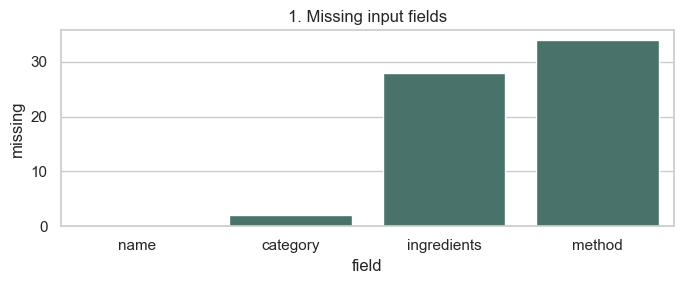

In [3]:
def normalize(v):
    if isinstance(v,str):return unicodedata.normalize('NFC',v).strip()
    if isinstance(v,list):return [normalize(x) for x in v]
    if isinstance(v,dict):return {k:normalize(x) for k,x in v.items()}
    return v
before=raw.to_dict('records'); normalized=[normalize(r) for r in before]
for group in pd.DataFrame(normalized).groupby('id'):
    assert len({json.dumps(r,sort_keys=True,ensure_ascii=False) for r in group[1].recipe})==1
clean=pd.DataFrame(normalized).drop_duplicates('id',keep='last').copy()
assert clean.id.nunique()==48 and clean.recipe.map(lambda r:bool(r['name'])).all()
assert set(clean.language)=={'ru','kk'}
assert clean.groupby('group').split.nunique().max()==1
assert not set(clean.query('split=="final"').group)&{r['group'] for r in old}
clean['n_ingredients']=clean.recipe.map(lambda r:len(r['ingredients']))
quality=pd.DataFrame([{'field':k,'missing':sum(not r.get(k) for r in raw.recipe)} for k in ['name','category','ingredients','method']])
audit={'raw_rows':len(raw),'clean_rows':len(clean),'duplicate_rows_removed':len(raw)-len(clean),
       'normalized_rows':sum(a!=b for a,b in zip(before,normalized)),'imputed_ingredients':0}
display(quality); print(audit)
quality.to_csv(OUT/'quality.csv',index=False)
(OUT/'cleaning.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
clean.to_json(OUT/'clean_inputs.json',orient='records',force_ascii=False,indent=2)
plt.figure(figsize=(7,3)); sns.barplot(data=quality,x='field',y='missing',color='#41796e'); plt.title('1. Missing input fields'); fig('01_missing')

## 2. EDA и разделение примеров

В обеих частях есть карточки с составом и без. Переводы одного блюда не
пересекают части. Признаки X: поля блюда, язык, тон, лимит, версия промпта.
Наблюдаемые результаты y: прохождение проверок, длина, время, токены и редакторская
оценка. Отдельного train нет: это разработка промпта, а не обучение классификатора.

n
split language completeness         
dev   kk       complete            8
               name_category_only  8
      ru       complete            8
               name_category_only  8
final kk       complete            4
               name_category_only  4
      ru       complete            4
               name_category_only  4

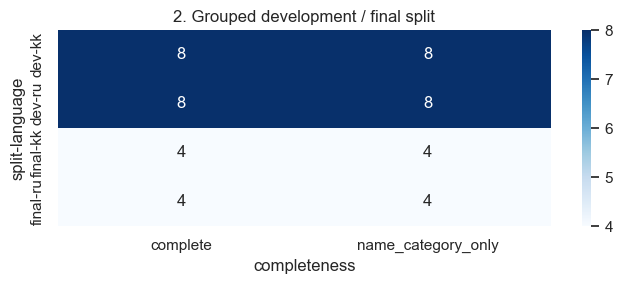

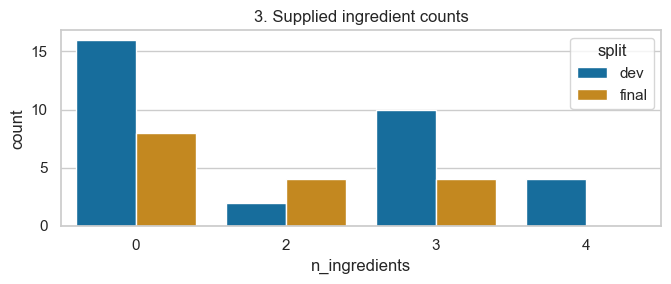

Frozen sources verified before held-out calls.


In [4]:
display(clean.groupby(['split','language','completeness']).size().rename('n').to_frame())
clean[['id','group','language','split']].to_csv(OUT/'split_manifest.csv',index=False)
plt.figure(figsize=(7,3)); sns.heatmap(pd.crosstab([clean.split,clean.language],clean.completeness),annot=True,fmt='d',cmap='Blues'); plt.title('2. Grouped development / final split'); fig('02_split')
plt.figure(figsize=(7,3)); sns.countplot(data=clean,x='n_ingredients',hue='split'); plt.title('3. Supplied ingredient counts'); fig('03_ingredients')
freeze=load('results/freeze.json'); manifest=load('results/final-manifest.json')
assert freeze['hashes']==manifest['hashes']
assert pd.Timestamp(freeze['at'])<pd.Timestamp(manifest['startedAt'])
assert all(hashlib.sha256(freeze['sources'][k].encode()).hexdigest()==v for k,v in freeze['hashes'].items())
print('Frozen sources verified before held-out calls.')

## 3. Протокол эксперимента и цена

Для каждого отложенного примера выполняются простой и подробный промпты в
чередующемся порядке. Подробный затем повторяется с предыдущим результатом.
Обе ветки используют одинаковую модель, общий таймаут и максимум одну попытку
исправления после отказа валидатора. Поэтому сравниваем и **первую попытку**,
и **итог логического запроса**. Все неудачные попытки и токены сохранены.
Простой промпт при исправлении тоже получает причину отказа; это уже не чистый
одношаговый baseline, что отражено отдельной метрикой первых попыток.

Публичный тариф на 07.10.2026: $0,20/млн входных, $0,02/млн кэшированных входных,
$0,25/млн записи кэша и $1,20/млн выходных токенов.
[Источник: официальная страница модели](https://developers.openai.com/api/docs/models/gpt-5.6-luna).
Цена 1 000 запросов = средняя сумма стоимостей **всех** попыток одного запроса × 1 000.
Один запрос возвращает четыре канала и вариант. Хостинг, налоги, региональные
надбавки и индивидуальный тариф не включены. Это расчёт по токенам, не счёт провайдера.

,n,accepted,first_pass,mean_s,p95_s,max_s,mean_tokens,usd_per_1000,provider_calls
strategy,,,,,,,,,
detailed,16,16,16,2.1401,2.5050,2.535,677.6250,0.2556,16
simple,16,14,0,4.4349,4.9338,5.035,598.1875,0.3833,32


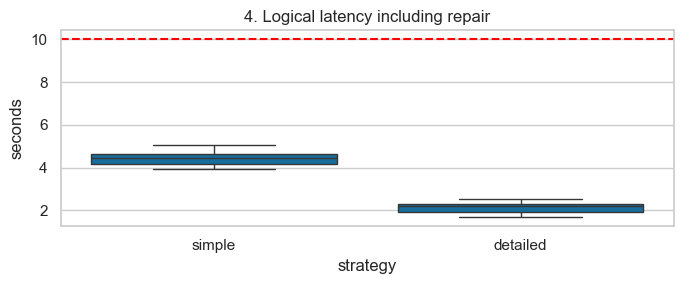

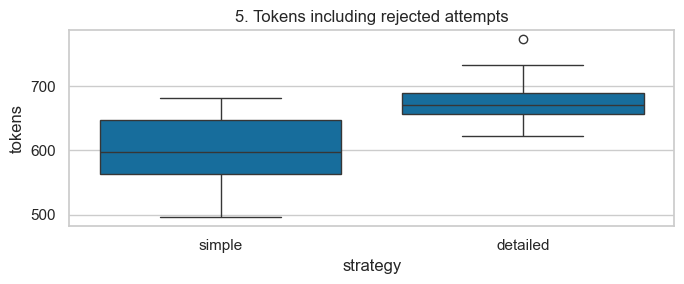

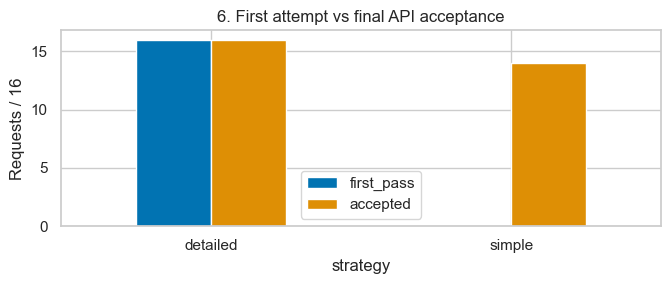

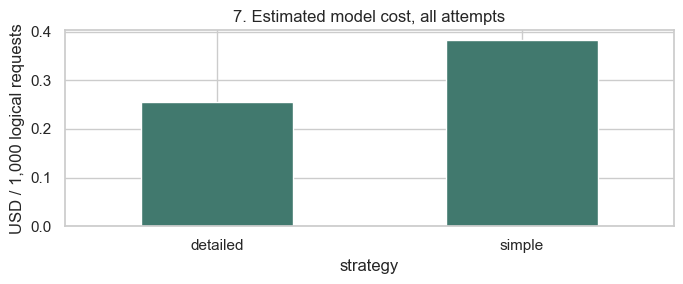

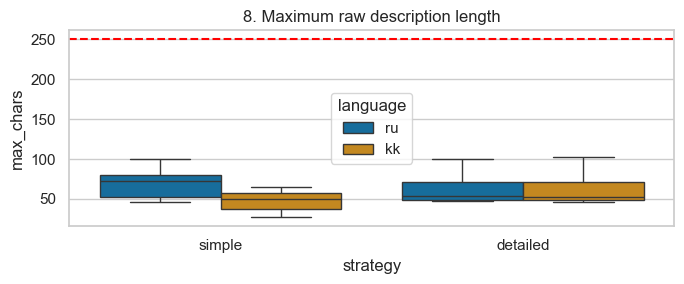

In [5]:
pricing=load('pricing.json'); rates=pricing['per_million']
def call_cost(c):
    u=c.get('response',{}).get('usage')
    if not u:return None
    d=u.get('prompt_tokens_details',{})
    cached=d.get('cached_tokens',0); written=d.get('cache_write_tokens',0)
    assert cached+written<=u['prompt_tokens']
    return ((u['prompt_tokens']-cached-written)*rates['input']+cached*rates['cached_input']+written*rates['cache_write']+u['completion_tokens']*rates['output'])/1e6
def summarize(r):
    costs=[call_cost(c) for c in r['calls']]
    raw=r['calls'][-1].get('response',{}).get('choices',[{}])[0].get('message',{}).get('content','{}')
    try:obj=json.loads(raw)
    except Exception:obj={}
    ts=list(obj.get('texts',{}).values())+[obj.get('variant','')]
    return dict(id=r['id'],group=r['input']['group'],language=r['input']['language'],tone=r['input']['tone'],
      strategy=r['strategy'],repetition=r['repetition'],accepted=r['accepted'],calls=len(r['calls']),
      first_pass=r['accepted'] and len(r['calls'])==1,seconds=r['elapsedMs']/1000,
      tokens=sum(c.get('response',{}).get('usage',{}).get('total_tokens',0) for c in r['calls']),
      usd=sum(costs) if all(c is not None for c in costs) else None,
      max_chars=max([len(t.encode('utf-16-le'))//2 for t in ts],default=0),
      error=r.get('error',{}).get('code'),text=obj.get('texts',{}).get('yandex',''))
final=lines('results/final.jsonl')
df=pd.DataFrame([summarize(r) for r in final])
assert len(df)==48 and not df.id.duplicated().any()
assert df.usd.notna().all()
primary=df.query('repetition==0').copy(); regen=df.query('repetition==1').copy()
assert len(primary)==32 and primary.groupby(['group','language']).strategy.nunique().eq(2).all()
summary=primary.groupby('strategy').agg(n=('id','size'),accepted=('accepted','sum'),first_pass=('first_pass','sum'),
    mean_s=('seconds','mean'),p95_s=('seconds',lambda x:x.quantile(.95)),max_s=('seconds','max'),
    mean_tokens=('tokens','mean'),usd_per_1000=('usd',lambda x:x.mean()*1000),provider_calls=('calls','sum'))
display(summary.round(4))
df.to_csv(OUT/'requests.csv',index=False); summary.to_csv(OUT/'comparison.csv')
plt.figure(figsize=(7,3)); sns.boxplot(data=primary,x='strategy',y='seconds'); plt.axhline(10,color='red',linestyle='--'); plt.title('4. Logical latency including repair'); fig('04_latency')
plt.figure(figsize=(7,3)); sns.boxplot(data=primary,x='strategy',y='tokens'); plt.title('5. Tokens including rejected attempts'); fig('05_tokens')
summary[['first_pass','accepted']].plot.bar(figsize=(7,3)); plt.xticks(rotation=0); plt.ylabel('Requests / 16'); plt.title('6. First attempt vs final API acceptance'); fig('06_acceptance')
summary.usd_per_1000.plot.bar(figsize=(7,3),color='#41796e'); plt.xticks(rotation=0); plt.ylabel('USD / 1,000 logical requests'); plt.title('7. Estimated model cost, all attempts'); fig('07_cost')
plt.figure(figsize=(7,3)); sns.boxplot(data=primary,x='strategy',y='max_chars',hue='language'); plt.axhline(250,color='red',linestyle='--'); plt.title('8. Maximum raw description length'); fig('08_lengths')

## 4. Перегенерация, тон и работа сайта

Перегенерация сравнивает все четыре канала после удаления пунктуации и изменения
регистра: одни кавычки или точка новым вариантом не считаются. Это проверка
изменения формулировки, а не гарантия заметного для человека разнообразия.
Тон дополнительно проверен на одном блюде во всех трёх настройках на RU/KK.
Это оценка формы подачи, не независимый стилистический тест.

Браузер использует собранный сайт → настоящий Express → native fetch к модели.
Сопоставлены ответ провайдера, JSON API, токены всех попыток и видимый текст.
Сбои проверены отдельно локальным HTTP 503 и задержкой: их нельзя выдавать за
реальную недоступность провайдера. Секреты в журналах отсутствуют.

In [6]:
def canon(t):return re.sub(r'[^\w]+',' ',t.lower()).strip()
regen_checks=[]
for r in final:
    if r['repetition']!=1:continue
    first=next(x for x in final if x['input']['id']==r['input']['id'] and x['strategy']=='detailed' and x['repetition']==0)
    changed=r['accepted'] and all(canon(r['result']['texts'][c])!=canon(first['result']['texts'][c]) for c in ['yandex','wolt','website','print'])
    regen_checks.append(dict(id=r['id'],changed_all_channels=changed,calls=len(r['calls']),seconds=r['elapsedMs']/1000))
display(pd.DataFrame(regen_checks))
tones=lines('results/tones.jsonl')
tone_rows=[dict(language=r['input']['language'],tone=r['input']['tone'],text=r['result']['texts']['yandex']) for r in tones]
tone_table=pd.DataFrame(tone_rows)
assert tone_table.groupby('language').text.nunique().eq(3).all()
display(tone_table)
browser=load('results/browser.json'); assert browser['passed']
contract=load('results/contract.json')
assert all(x['allWithinLimit'] if x['accepted'] else x['response']['error']['code']=='LLM_CONSTRAINT_FAILED' for x in contract['checks'])
display(pd.DataFrame([dict(language=x['input']['language'],limit=x['input']['maxLength'],accepted=x['accepted'],status=x['status']) for x in contract['checks']]))
assert all(x['visibleMatchesProvider'] for x in browser['live'])
assert all(x['generationsBefore']==x['generationsAfter'] for x in browser['injectedFaults'])
display(pd.DataFrame([dict(language=x['language'],seconds=x['renderElapsedMs']/1000,
                         matches=x['visibleMatchesProvider'],response_id=x['response']['providerResponseId']) for x in browser['live']]))
display(pd.DataFrame([dict(fault=x['fault'],status=x['status'],message=x['visibleError']) for x in browser['injectedFaults']]))

,id,changed_all_channels,calls,seconds
0,lentil-ru:detailed:1,True,1,2.377
1,lentil-kk:detailed:1,True,1,2.448
2,beet-ru:detailed:1,True,1,1.803
3,beet-kk:detailed:1,True,1,2.386
4,potato-ru:detailed:1,True,1,2.460
5,potato-kk:detailed:1,True,1,2.487
6,compote-ru:detailed:1,True,1,2.400
7,compote-kk:detailed:1,True,1,2.580
8,khachapuri-ru:detailed:1,True,2,3.418
9,khachapuri-kk:detailed:1,True,1,2.568


,language,tone,text
0,ru,editorial,"Овсяная каша — овсяные хлопья, молоко и соль; приготовлена варкой."
1,ru,bistro,В меню: овсяная каша из овсяных хлопьев на молоке с солью. Варка.
2,ru,concierge,"Предлагаем овсяную кашу из овсяных хлопьев, молока и соли, приготовленную методом варки."
3,kk,editorial,"Сұлы ботқасы — сұлы үлпектері, сүт және тұздан дайындалып, қайнатылады."
4,kk,bistro,"Мәзірде: Сұлы ботқасы — сұлы үлпектері, сүт және тұздан дайындалады. Қайнатылып ұсынылады."
5,kk,concierge,"Ұсынамыз: «Сұлы ботқасы» — сұлы үлпектері, сүт және тұздан дайындалып, қайнатылады."


,language,limit,accepted,status
0,ru,60,False,502
1,kk,60,True,201
2,ru,250,True,201
3,ru,250,True,201


,language,seconds,matches,response_id
0,ru,2.670,True,chatcmpl-EW5nHKI22s76e1oFsGvojnELrb3P4
1,ru,4.219,True,chatcmpl-EW5nMWfK6M3eln1693nHvqQetanCc
2,kk,2.714,True,chatcmpl-EW5nOjhEzGB1JZofGfMl4HfH5bu3V


,fault,status,message
0,http503,502,Провайдер генерации временно недоступен. Повторите запрос позже.
1,timeout,504,Генерация заняла слишком много времени. Повторите запрос.


## 5. Проверка содержания и ограничения

Codex просмотрел четыре канала и вариант подробных ответов новой выборки.
Новых ингредиентов, количества соли и сенсорных свойств в выданных подробных
ответах не обнаружено. **Однако один ответ о хачапури добавил «в бистро»**:
тип заведения не был задан. Этот пример отмечен для редакторской правки;
итоговая выборка не используется для подстройки кода задним числом.
У простого промпта даже после исправления часто остаётся служебная фраза в
`variant`, а не описание блюда. Принятие API не равно редакторскому одобрению.
При дополнительном лимите 60 символов один RU-запрос вернул контролируемую ошибку:
после попытки исправления один канал всё ещё превышал лимит. Такой текст не был
показан как успешный. Из четырёх дополнительных API-проверок успешны три; все
успешные ответы укладываются в заданные ограничения. На основном лимите 250
все первичные подробные ответы итоговой выборки приняты.

Оценка выполнена ИИ, не независимым человеком. Подготовлена таблица для рецензента:
проверить факты, естественность RU/KK и соответствие тону. Носитель казахского
пока её не заполнял. Нельзя заявлять нулевой риск галлюцинаций или редакторскую
готовность всех текстов. В отдельных ответах видны повторяемость и канцелярский стиль.

Словарь фактов ограничен и может давать ложные срабатывания. Реальный трафик,
нагрузка, эффект LinUCB на конверсию и стоимость хостинга здесь не измерялись.
Нет статистического доказательства обобщения на все меню: независимых новых блюд всего восемь.

In [7]:
review_rows=[]
for r in final:
    if r['strategy']!='detailed':continue
    raw=r['calls'][-1]['response']['choices'][0]['message']['content']
    flag=r['id']=='khachapuri-ru:detailed:0'
    review_rows.append(dict(id=r['id'],source=json.dumps(r['input']['recipe'],ensure_ascii=False),
        answer=raw,sha256=hashlib.sha256(raw.encode()).hexdigest(),
        codex_factual_review='venue claim: в бистро, not supplied' if flag else 'no unsupported ingredient or concrete fact detected in this reading',
        human_reviewer='',human_language_score='',human_factual_pass='',human_tone_pass='',human_notes=''))
pd.DataFrame(review_rows).to_csv(OUT/'human_review.csv',index=False)
display(pd.DataFrame(review_rows)[['id','codex_factual_review']].head(10))
calls=[c for r in final for c in r['calls']]
all_runs=[r for name in ['dev','refined','tones','final'] for r in lines(f'results/{name}.jsonl')]
all_live_calls=[c for r in all_runs for c in r['calls']]+[c for e in [browser,contract] for c in e['calls'] if c.get('response',{}).get('usage')]
result=dict(final=summary.reset_index().to_dict('records'),final_regenerations=len(regen_checks),
    regeneration_changed=sum(x['changed_all_channels'] for x in regen_checks),
    final_max_seconds=float(df.seconds.max()),final_model_calls=len(calls),
    total_model_calls=len(all_live_calls),total_tokens=sum(c['response']['usage']['total_tokens'] for c in all_live_calls),
    total_estimated_usd=sum(call_cost(c) for c in all_live_calls),browser_passed=browser['passed'],
    tone_examples=6,figures=8,human_review_completed=False,qualitative_venue_flags=1,
    contract_successes=sum(x['accepted'] for x in contract['checks']),contract_checks=len(contract['checks']),
    regeneration_usd_per_1000=float(regen.usd.mean()*1000),
    pricing_source=pricing['source'],pricing_date=pricing['checked_on'])
(OUT/'metrics.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
display(result)

,id,codex_factual_review
0,lentil-ru:detailed:0,no unsupported ingredient or concrete fact detected in this reading
1,lentil-ru:detailed:1,no unsupported ingredient or concrete fact detected in this reading
2,lentil-kk:detailed:0,no unsupported ingredient or concrete fact detected in this reading
3,lentil-kk:detailed:1,no unsupported ingredient or concrete fact detected in this reading
4,beet-ru:detailed:0,no unsupported ingredient or concrete fact detected in this reading
5,beet-ru:detailed:1,no unsupported ingredient or concrete fact detected in this reading
6,beet-kk:detailed:0,no unsupported ingredient or concrete fact detected in this reading
7,beet-kk:detailed:1,no unsupported ingredient or concrete fact detected in this reading
8,potato-ru:detailed:0,no unsupported ingredient or concrete fact detected in this reading
9,potato-ru:detailed:1,no unsupported ingredient or concrete fact detected in this reading


{'final': [{'strategy': 'detailed',
   'n': 16,
   'accepted': 16,
   'first_pass': 16,
   'mean_s': 2.140125,
   'p95_s': 2.505,
   'max_s': 2.535,
   'mean_tokens': 677.625,
   'usd_per_1000': 0.25565,
   'provider_calls': 16},
  {'strategy': 'simple',
   'n': 16,
   'accepted': 14,
   'first_pass': 0,
   'mean_s': 4.4349375,
   'p95_s': 4.93375,
   'max_s': 5.035,
   'mean_tokens': 598.1875,
   'usd_per_1000': 0.383325,
   'provider_calls': 32}],
 'final_regenerations': 16,
 'regeneration_changed': 16,
 'final_max_seconds': 5.035,
 'final_model_calls': 66,
 'total_model_calls': 106,
 'total_tokens': 64493,
 'total_estimated_usd': 0.026846600000000005,
 'browser_passed': True,
 'tone_examples': 6,
 'figures': 8,
 'human_review_completed': False,
 'qualitative_venue_flags': 1,
 'contract_successes': 3,
 'contract_checks': 4,
 'regeneration_usd_per_1000': 0.3122125,
 'pricing_source': 'https://developers.openai.com/api/docs/models/gpt-5.6-luna',
 'pricing_date': '2026-10-07'}

## 6. Воспроизведение

Python-зависимости: pandas, numpy, matplotlib, seaborn, nbformat, nbclient,
nbconvert, ipykernel (точные версии в `requirements.txt`). Run All в чистом ядре
пересчитывает все показатели из встроенных данных, не отправляя запросы.

Для нового живого прогона: сохранить текущую папку results, затем из корня приложения
выполнить `node experiments/llm-v2/run.mjs dev`, `... tones`, `... freeze`,
`... final`. Создать новый снимок Notebook и заново проверить смысл ответов.
Ключ хранится только в `.env`, новый запуск платный. В логах остаются полные
промпты, ответы, request/response ID, временные метки и usage каждой попытки.
Успех или текст не обязаны повториться: модель и сеть недетерминированы.

Для сдачи: этот Notebook, HTML-копия, PDF-отчёт, PPTX/PDF-презентация и исходный
код эксперимента. Предыдущая итерация остаётся в `experiments/llm` для аудита.